## 1. Motivation and model overview {#motivation-and-model-overview}

Residual risk estimates the probability of a terminal individual-possession loss given that the player successfully completes the current one-second carry (see [Possession segmentation and context](../setup/possession_and_checkpoint_setup.ipynb)). The model evaluates the state at the beginning of that carry, using only the information available at that frame. The outcome of the individual possession remains open after a successful carry, so the prediction concerns the remaining sequence of individual control.

An individual possession unfolds as an alternation of choice and execution: in each state the player chooses to pass or to carry, the chosen action is executed with some probability of success, and the possession continues from a new state. A successful carry leads to such a new state, and the probability that the possession eventually ends in a loss depends on all later choices and executions. Residual risk approximates this remaining iteration with a single classifier, which maps the state at the start of the carry directly to the probability of eventual terminal loss.

Let $Y=1$ denote a terminal individual-possession loss, that is, a possession that ends in a failed pass, a direct possession loss or a clearance, and $Y=0$ a possession that ends in a completed pass or a foul suffered, according to the conventions specified in the [residual-risk benchmark](../../benchmarks/05_residual_risk.qmd). Using the same state notation as action selection, let $s$ denote the current game state and $A$ the selected action. For this state, the conditional target is

$$
r(s)=P(Y=1\mid s,\,A=\mathrm{carry},\,\text{successful one-second carry}).
$$

Consequently, the probability of a terminal outcome without loss, under the same condition, is $1-r(s)$.

We estimate $r(s)$ with a regularized XGBoost classifier [@chen2016xgboost], which takes a vector of features summarizing the game state and returns the probability of terminal loss. The features are described first, followed by the likelihood used to train the model.

## 2. Model inputs {#model-inputs}

Residual risk uses the same state-based features and construction procedures as the [action-selection vignette](../04_action_selection/04_action_selection.ipynb), with two changes.

- **Carry probability $P(\mathrm{carry})=1-q(s)$.** The chance that the player chooses to carry in state $s$, where $q(s)=P(A=\mathrm{pass}\mid s)$ is the pass-choice probability defined in action selection. It is computed by the action-selection model from its own inputs, including the number of completed one-second carries, and is taken from that model without refitting. In training, it is cross-fitted so that every state is scored by an action-selection model that did not see its match, as described in the [benchmark](../../benchmarks/05_residual_risk.qmd). Together with the carry-execution success probability $1-d(s)$, already among the shared features, which gives the chance that the carry succeeds, it describes both the choice and the execution of carrying.
- **Elapsed time.** The time elapsed since the beginning of the individual possession, measured at the prediction frame, how long the player has already been on the ball. It replaces the count of completed one-second carries, enters residual risk only, and uses no information after the prediction frame.

These changes yield 31 conceptual inputs, including the two categorical context variables. The classifier returns its native logistic probabilities.

Context-label meanings and the `previous_action` convention are defined in the [User guide](../setup/possession_and_checkpoint_setup.ipynb#context-labels).

## 3. Likelihood and learning {#likelihood-and-learning}

For feature vector $z_i$ and binary terminal label $y_i\in\{0,1\}$, the tree ensemble produces a score $f_\psi(z_i)$ and the logistic residual-loss probability

$$
\widehat r_i=\frac{1}{1+\exp[-f_\psi(z_i)]}.
$$

The parameters are fitted by minimizing the Bernoulli negative log-likelihood with the usual tree-complexity penalty,

$$
\mathcal L(\psi)=-\sum_i\left[y_i\log\widehat r_i+(1-y_i)\log(1-\widehat r_i)\right]+\Omega(\psi).
$$

Training observations are states preceding completed, successful one-second carries, with the label taken from the eventual terminal outcome of the same individual possession. Cohort verification, outcome conventions, model selection and held-out evaluation are documented in the [benchmark](../../benchmarks/05_residual_risk.qmd).

## 4. Feature importance and interpretation {#feature-importance-and-interpretation}

The figure reports XGBoost total split gain, normalized within each fitted ensemble. One-hot encoded levels are aggregated into their original conceptual features. Bars represent the installed full-data model, while the five outer-fold estimates indicate variability across fitted models; their ranges are descriptive.

![Feature importance of the residual-risk model.](../../figures/feature_importance_residual_risk.png)

Accessible space and the configuration of subsequent passing options are prominent predictors. BCOS accounts for 14.21% of production split gain and ranks between first and fourth across the five outer folds. This suggests that the carrier's available space provides information about terminal individual-possession loss even after conditioning on a successful one-second carry.

The number of opponents ahead of likely completed-pass destinations contributes 10.30% and ranks first or second across folds. The model therefore relies on immediate conditions around the carrier and on the spatial configuration of plausible subsequent passes. The estimated probability of successful one-second carrying (8.83%) and expected pass success (8.01%) are also prominent, linking the forecast to immediate execution conditions and available alternatives. The rank of expected pass success varies substantially across folds, so its production importance is less stable.

Team-line position under failed-pass outcomes (5.60%) and own-team xT under successful-pass outcomes (5.24%) further indicate that the model uses the tactical structure of potential continuations. Overall, these rankings are consistent with residual risk depending on both the carrier's freedom of movement and the quality of available options.

Split gain describes how the fitted ensemble uses its inputs. Correlated inputs can substitute for one another, and features with more potential split points may receive higher gain. Further diagnostics are available in the [feature-importance analysis](../../data/benchmarks/feature_importance/README.md).


## 5. Application to a game state {#application-to-a-game-state}

Auckland FC–Newcastle: L. Gillion completes the one-second carry starting at checkpoint 32927, then loses possession; K. Grozos takes control for Newcastle. The second frame is the beginning of the next individual possession. Set `SKILLCORNER_OPENDATA` to your local open-data repository ([Data setup](../../data.qmd)).


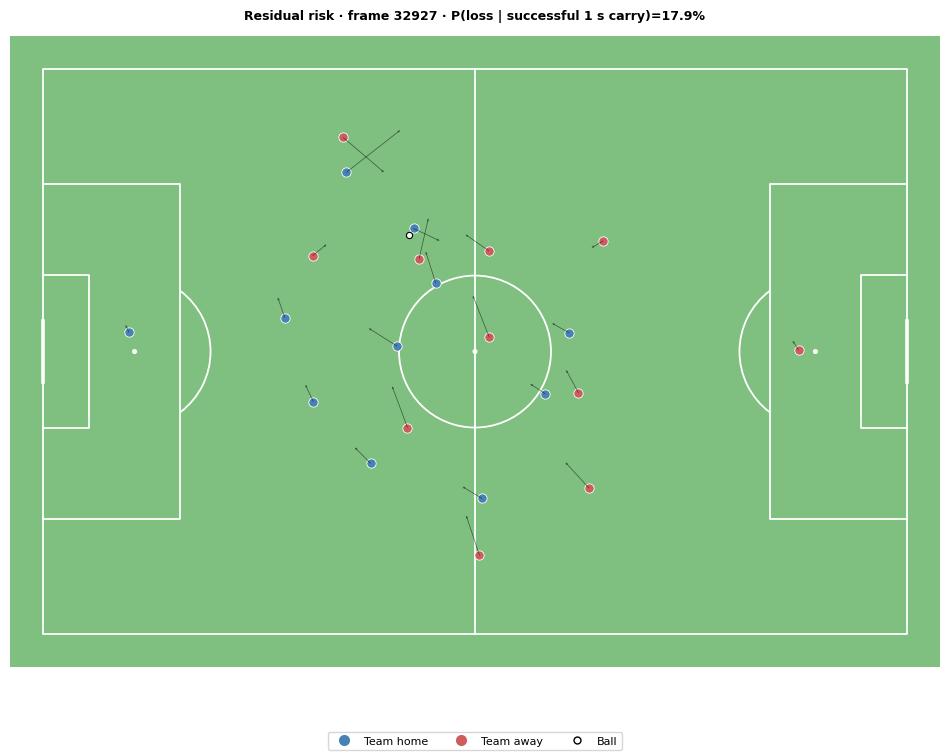

In [5]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
import jax

jax.config.update("jax_enable_x64", True)
from PRESS import PRESS

opendata = Path(os.environ.get("SKILLCORNER_OPENDATA", Path.cwd().parent / "opendata"))
match_dir = opendata / "data/matches/1886347"
press = PRESS.from_skillcorner(match_dir)
frame_id = 32927

# Observed context: getters resolve the frame and possession annotations.
frame = press.get_frame(frame_id).iloc[0]
context = press.get_frame_context(frame_id)
match_clock_min = pd.to_timedelta(frame.timestamp).total_seconds() / 60

# Score is absent from these tracking rows: read the current possession's
# dynamical event rather than inserting a constant in the model call.
possessions = press.get_player_possessions()
current_possession = possessions.loc[
    possessions.frame_start.le(frame_id) & possessions.frame_end.ge(frame_id)
].iloc[0]
events = pd.read_csv(
    opendata / "data/matches" / match_dir.name / f"{match_dir.name}_dynamic_events.csv",
    low_memory=False,
)
origin = events.loc[
    events.event_type.eq("player_possession")
    & events.event_id.eq(current_possession.possession_id)
].iloc[0]
score_difference = float(origin.team_score - origin.opponent_team_score)

from PRESS.model import PassSelectionModel

xT_grid = PassSelectionModel.pretrained().xt_grid
result = press.compute_risk_frame(
    frame_id, xT_grid, keep_details=True,
    start_type=context["start_type"], previous_action=context["previous_action"],
    completed_canonical_drives=context["completed_canonical_drives"],
    match_clock_min=match_clock_min, score_difference_prefix=score_difference,
)

# Reuse the preliminary BCOS feature evaluated by the production workflow.
area = press.get_bcos_result(frame_id)["BCOS area"]

from PRESS.model import ActionSelectionModel, ResidualRiskModel

state = press.get_state(frame_id)
context = press.get_frame_context(frame_id)
field = result["PPCF"]
action_model = ActionSelectionModel.pretrained()
residual_model = ResidualRiskModel.pretrained()
features = residual_model.build_features(
    action_model=action_model, time_since_start=press.get_elapsed_time(frame_id),
    x_bc=state["x_bc"], v_bc=state["v_bc"],
    r_atts=state["r_atts"], r_defs=state["r_defs"],
    attacking_side=state["attacking_side"], targets=field["grid"],
    pass_selection_probabilities=field["Pass selection probabilities"],
    pass_success_probability=field["Pass probability"],
    bcos=area, ball_drive_loss=result["BALL_DRIVE_RISK"]["Ball drive risk"],
    start_type_raw=context["start_type"], previous_action_raw=context["previous_action"],
    match_clock_min=match_clock_min, score_difference_prefix=score_difference,
    completed_canonical_drives=context["completed_canonical_drives"],
    pitch_length=state["pitch_length"], pitch_width=state["pitch_width"],
)
c = float(residual_model.predict_features(features)[0])

from PRESS.visualization import plot_frame

plot_frame(press, frame_id, title=f"Residual risk · frame {frame_id} · P(loss | successful 1 s carry)={c:.1%}")
plt.savefig("figures/vignette_12_residual_real_pitch.png", dpi=170)
plt.savefig("figures/vignette_12_residual_real_pitch.svg")
plt.close()


![Residual-risk prediction at the start of the successful one-second carry.](../../figures/vignette_12_residual_real_pitch.png)

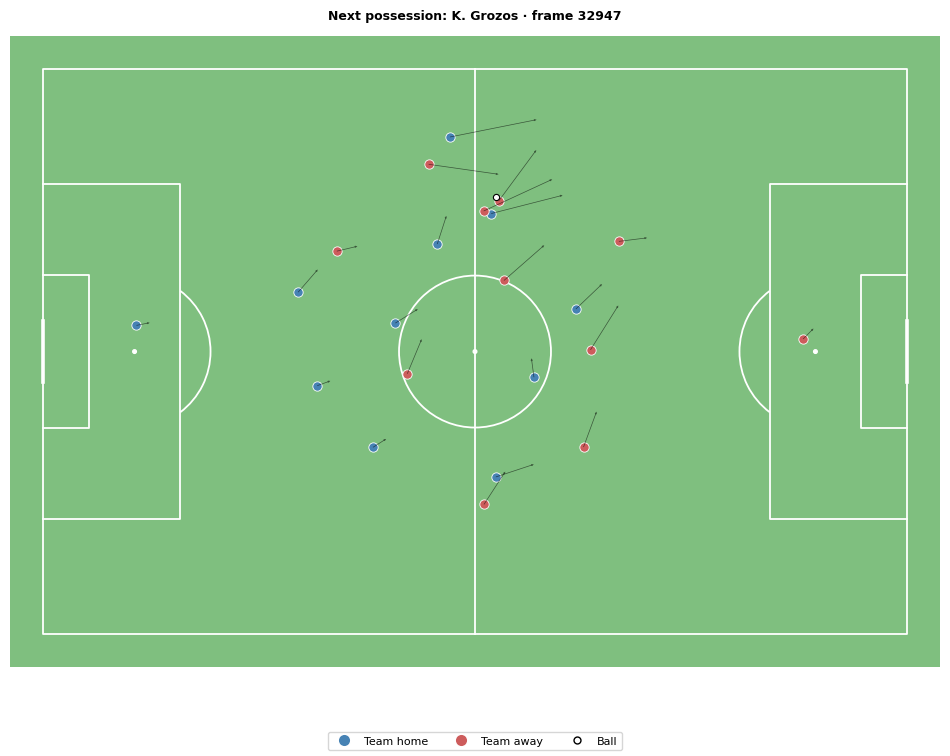

In [7]:
from PRESS.visualization import plot_frame

next_frame = 32947
plot_frame(press, next_frame, title="Next possession: K. Grozos · frame 32947")
plt.savefig("figures/vignette_12_residual_next_pitch.png", dpi=170)
plt.savefig("figures/vignette_12_residual_next_pitch.svg")
plt.close()


![Beginning of the next individual possession after the loss.](../../figures/vignette_12_residual_next_pitch.png)